Name: Sana Raza

Labpartner(s)

In [1]:
#import statements go here
import numpy as np
import matplotlib.pyplot as plt

# Class 12.2

# Warmup 12.2

Follow up with working on logging into the LSU HPC and finishing the warmup from last time. You may need to run a vpn. Let's get everyone spun up on this. If you're already there, help your fellow students and go dig into the documentation more. We'll do some more on this next week. Report here 1) have you been able to ssh in? 2) have you been able to access the ondemand site and open a jupyter notebook?

# Lecture 12.2

### Announcements
  
We are going to do an advanced lab today!


### Agenda
- Predator prey modeling. We are going to actually do some scientific modelng today!

## Predator Prey Modeling

See what this lab was based on here: 

https://github.com/numerical-mooc/assignment-bank/blob/master/Lessons.and.Assignments/Predator.Prey.Model/Predator.Prey.Model.ipynb

For a more advanced example in predator prey modeling:

https://waterprogramming.wordpress.com/tag/predator-prey/

Modeling the zombie aplocalypse:

https://scipy-cookbook.readthedocs.io/items/Zombie_Apocalypse_ODEINT.html



###  12.2.1 Lotka-Volterra Equations

The Lotka–Volterra equations, also known as the predator–prey equations, are a pair of first-order, non-linear, differential
equations. They are frequently used to describe the dynamics of biological systems in which two species interact, one as a predator and
the other as prey. You can read more about this from Wikipedia <http://en.wikipedia.org/wiki/Lotka-Volterra_equation>.

#### Equations describing the system

 Their populations change with time according to the following pair of equations:

$ dx/dt = x ( \alpha - \beta y  ) $

$ dy/dt = -y( \gamma - \delta x ) $

Where, $x$ is the number of prey (e.g., phytoplankton), $y$ is the number of predators (e.g., zooplankton). $dx/dt, dy/dt$ gives the rate of change of their respective populations over 
time $t$. $\alpha, \beta, \gamma, \delta $ are the parameters describing the interaction between the two species. This models makes some assumptions about 
the predator and prey. You can read about them from the Wikipedia page mentioned above.

The above equations can be written in a slightly different form to interpret the physical meaning of the four parameters used.

1.Rate equation for prey

$dx/dt = \alpha x - \beta x y $

The prey population (x) is presumed to have unlimited supply of food, $\alpha x$ represents the rate of population growth of prey. Rate of decrease of population of prey is assumed to be proportional to the rate at which predator and prey encounter each other, given by $ \beta y x$

2.Rate equation for predator

$ dy/dt = \delta x y -\gamma y $

For the predator population (y), $\delta x y $ gives the rate of growth of predator population. Note that this is similar to the rate of decrease of population of prey. The second term $\gamma y $ gives the rate of population decrease for predators due to natural death or emigration.

### 12.2.2 Numerical solution using Python

A simple python code for solving these equations is shown below.

In [2]:
# import required libraries
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# set the parameters. I just took these from one of the samples, we will play around with them later
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [4]:
#define the time stepping scheme - Euler forward or "shooting" method

def euler_step(u, f, dt):
    """Returns the solution at the next time-step using Euler's method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    
    return u + dt * f(u)

In [5]:
# define the function that represents the Lotka-Volterra equations
# u is the x,y state of the system, what the population is at a given time.
# u = [x,y] on array with both the predetor and prey variables

def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x)])


In [6]:
# Now solve the system


# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])


In [7]:
u_euler

array([[10.,  2.],
       [ 0.,  0.],
       [ 0.,  0.],
       ...,
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.]], shape=(1501, 2))

In [8]:
n = 0
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [9]:
u_euler

array([[10.  ,  2.  ],
       [ 9.86,  2.12],
       [ 0.  ,  0.  ],
       ...,
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ]], shape=(1501, 2))

In [10]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [11]:
u_euler

array([[10.        ,  2.        ],
       [ 9.86      ,  2.12      ],
       [ 9.7077616 ,  2.244232  ],
       ...,
       [ 0.87954346,  0.04493602],
       [ 0.88786462,  0.04353381],
       [ 0.89627944,  0.04217898]], shape=(1501, 2))

We will now plot the variation of population for each species with time.

In [12]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

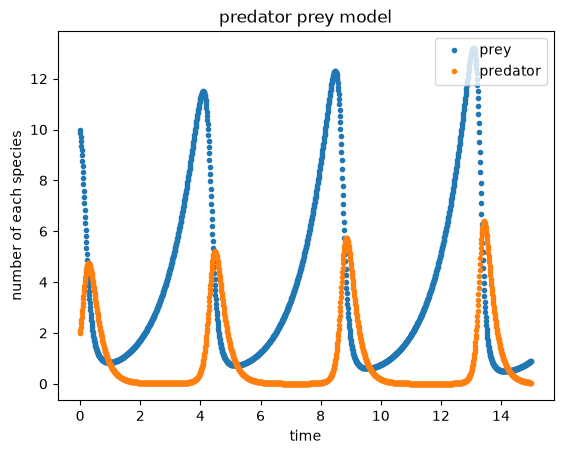

In [13]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Let's think a bit about what this solution means, what is going on here?

What happens if we start with different initial conditions? Like more prey and less predators.

In [14]:
# initial conditions (initial populations):
x0 = 15. # initial prey amount
y0 = 0.001 # initial predator amount
t0 = 0.

In [15]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [16]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

What happened?


In the start, there were almost no predators (0.001). Hence, the prey actually grows to about 23. Then, with so much of the food, the predators also grew very fast and hence, reach about 13 before time 1. The prey crashes to almost zero as well. Then the predators starve and then drop to almost zero too. The prey, in turn, slowly recover and then around time 8, there is another huge boom (here, prey is about 26 and the predators is about 16). Hence, starting far from the steady state also gives very extreme boom-and-crash cycles.

Text(0.5, 1.0, 'predator prey model')

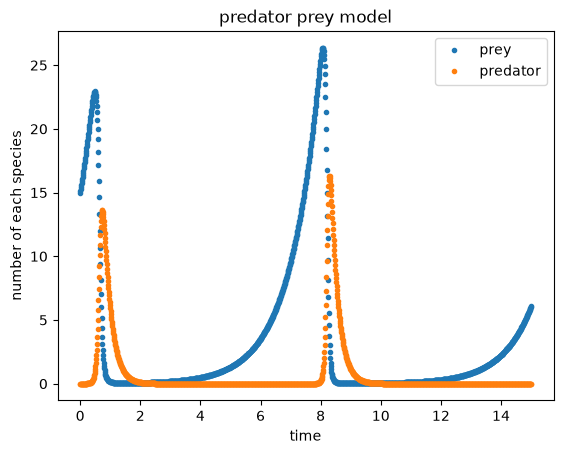

In [17]:
# breaking up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What if we start with the same amount of prey and predators?

In [18]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [19]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [20]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

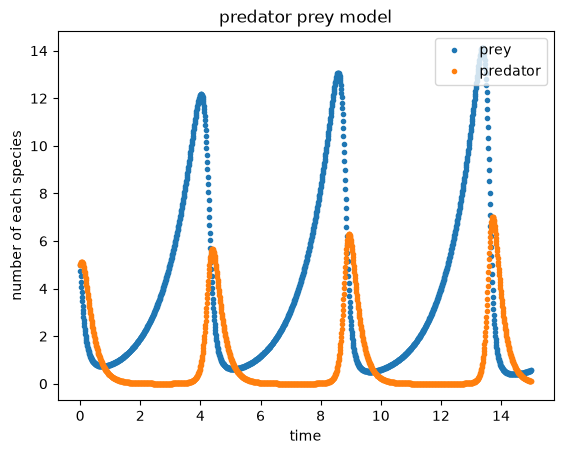

In [21]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

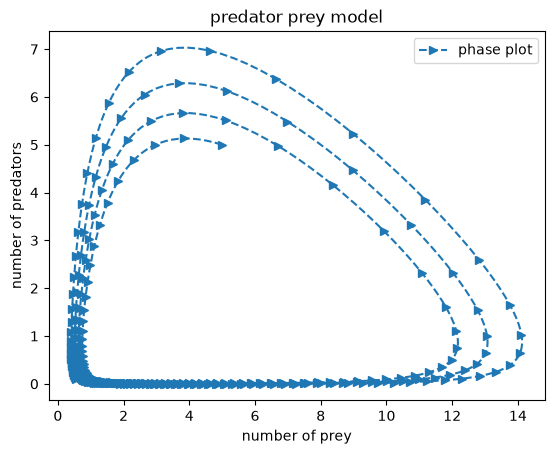

In [22]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

What happened?

Let's mess around with the model parameters. What if the prey grow faster?

In [23]:
# setting the parameters
alpha = 10.
beta = 1.2
gamma = 4.
delta = 1.

In [24]:
# initial conditions

x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [25]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

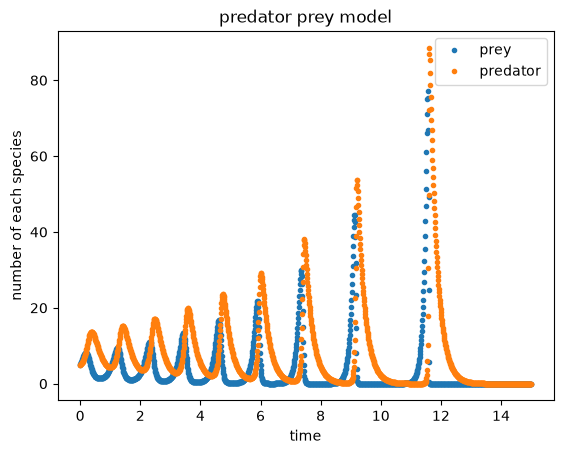

In [26]:
# breaking up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What happened?

### 12.2.3 System behavior

A better understanding of the system behavior can be obtained by a phase plot of the population of predators vs. the population of prey. It will tell us if the system sustains or collapses over time. For the choice of parameters $ \alpha, \beta, \gamma $ and $ \delta $ made above, we see that the maximum population of each species keeps increasing each cycle. You can read more about that in the Wikipedia link mentioned above.

Text(0.5, 1.0, 'predator prey model')

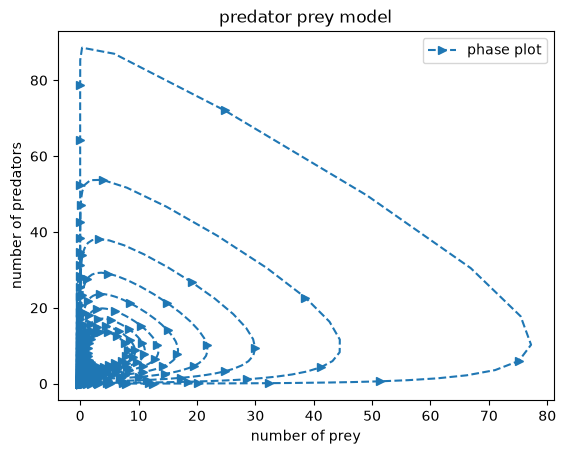

In [27]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

# Lab 12.2

#### E.1 How does timestep affect the solution?
Modify the timestep (or time increment) dt. How does this affect your solutions? Plot both the timeseries and the phase plots. Try making dt 10 times bigger (dt = 0.1) and 10 times smaller. Describe what happens to your results. What happens if you make dt 100 times smaller?

In [28]:
# first using the same initial values
alpha = 1
beta = 1.2
gamma = 4
delta = 1

x0 = 10 
y0 = 2    
T = 15.0   


# putting everyting in a function / loop
def run_model(x0, y0, dt, step=euler_step, func=f):
     # number of time steps
    N = int(T/dt) + 1  

      # array to save prey (column 0) and predator (column 1)
    u = np.zeros((N, 2))    
    # initial conditions
    u[0] = np.array([x0, y0])   
    for n in range(N-1):             
        u[n+1] = step(u[n], func, dt)
    time = np.linspace(0.0, T, N)
    return time, u

# function to make the timeseries plot along with the phase plot side by side
def plot_model(time, u, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(time, u[:,0], label='prey')
    ax1.plot(time, u[:,1], label='predator')
    ax1.set_xlabel("time")
    ax1.set_ylabel("number of each species")
    ax1.legend(loc='upper right')
    ax1.set_title(title)

    ax2.plot(u[:,0], u[:,1])
    ax2.set_xlabel("number of prey")
    ax2.set_ylabel("number of predators")
    ax2.set_title("phase plot, " + title)
    return ax1, ax2

dt = 0.1  smallest prey number: -4.682  largest prey number: 26.005
dt = 0.01  smallest prey number: 0.495  largest prey number: 13.219
dt = 0.001  smallest prey number: 0.86  largest prey number: 11.047
dt = 0.0001  smallest prey number: 0.898  largest prey number: 10.871


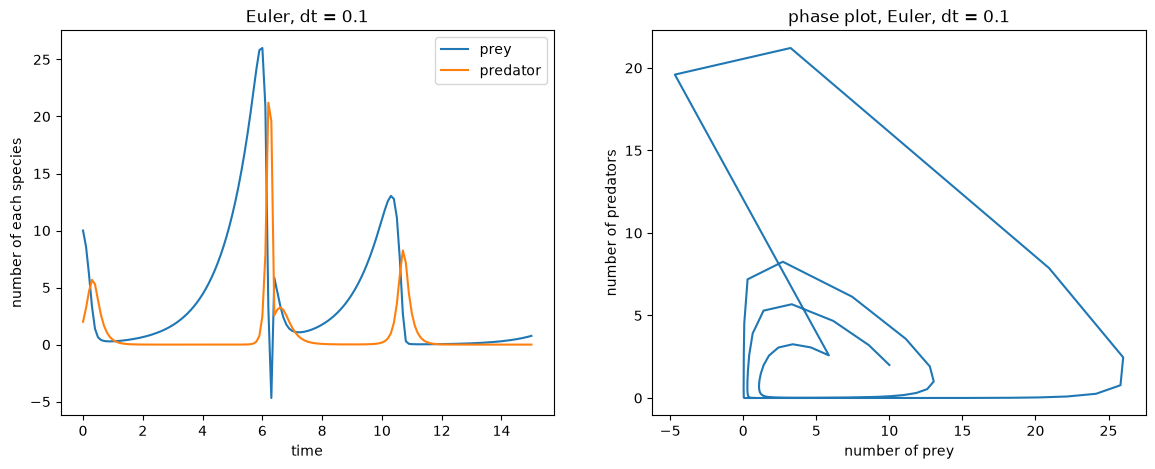

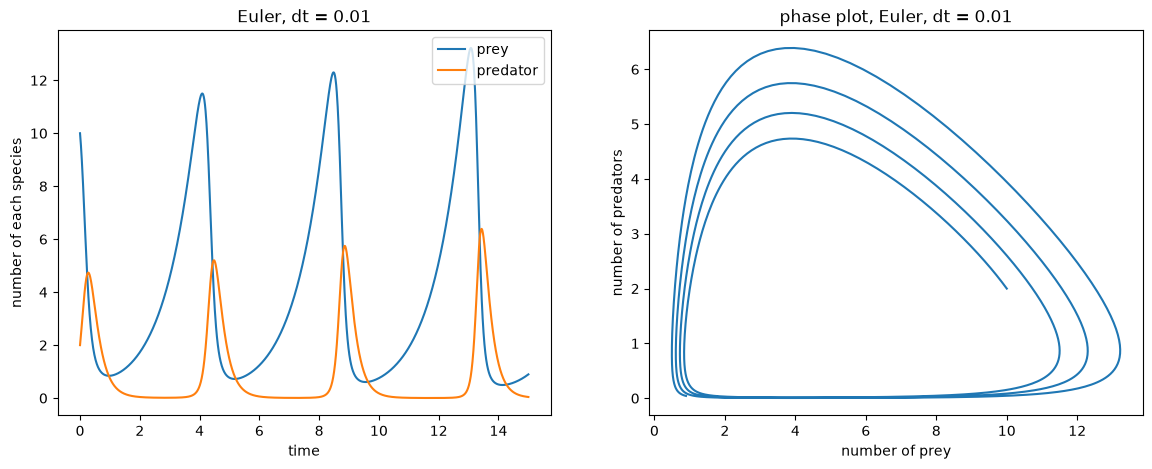

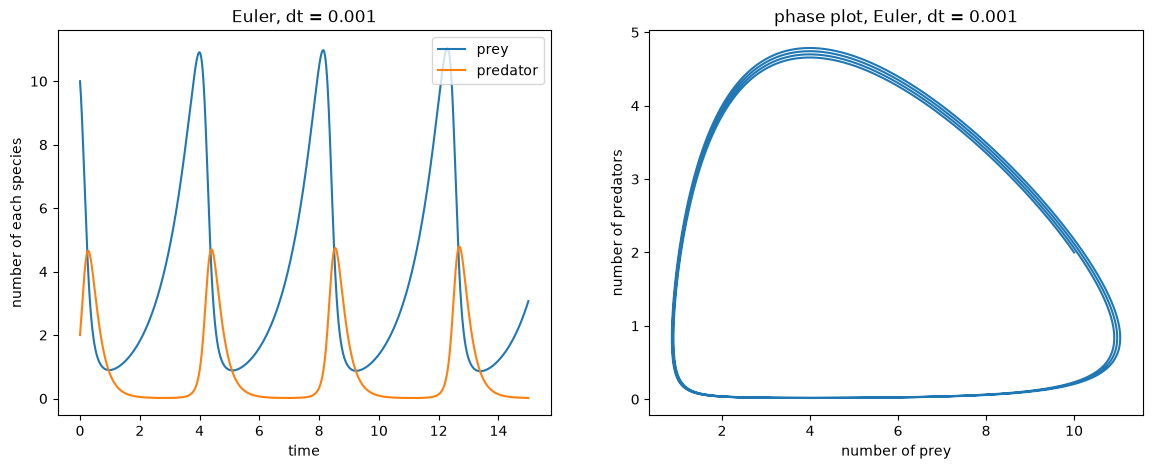

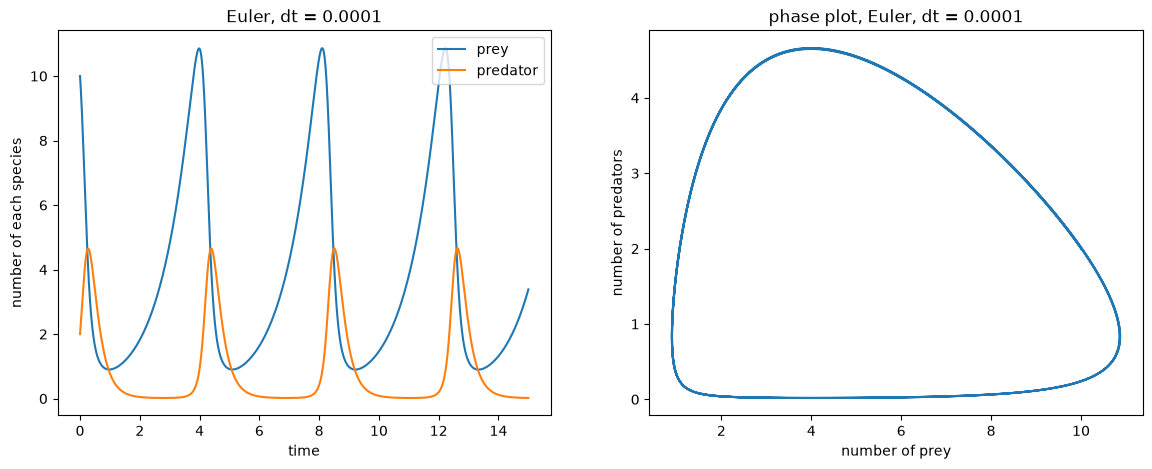

In [29]:
# now run the model with dt that is 10x bigger, 
# dt = 0.1 which is 10x bigger, 0.01 is the original, 0.001 is 10x smaller, and then 0.0001 is 100x smaller

for dt in [0.1, 0.01, 0.001, 0.0001]:
    time, u = run_model(x0, y0, dt)
    plot_model(time, u, "Euler, dt = " + str(dt))
    print("dt =", dt, " smallest prey number:", u[:,0].min().round(3), " largest prey number:", u[:,0].max().round(3))

#### E.2 Adding the steady state

The steady state(s) of the system are found by setting the population equations to zero, that is the solution to when the population is not changing. This is also called a "fixed point" of the equations, since if the populations start there they stay there, i.e. are fixed.

Find the steady states of the system using algebra. Plot the fixed point (steady state population) of the system on both the timeseries and phase space plots. Describe where the fixed point is in the phase space plot and plot it. What happens if you start at the steady state? What happens if you start near the steady state?

$\alpha x - \beta x y  = 0$

$\delta x y -\gamma y  = 0$



For prey, it is the following:

$x(\alpha - \beta y) = 0$, so $x = 0$ or $y = \alpha/\beta$

For predator, it is the following:

$y(\delta x - \gamma) = 0$, so $y = 0$ or $x = \gamma/\delta$

Both equations needs to be zero at the same time, hence, there are two steady states in here:

1. $x = 0, y = 0$ (both species are gone)
2. $x = \gamma/\delta = 4/1 = 4$ prey, $y = \alpha/\beta = 1/1.2 = 0.833$ predators

In [30]:
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

x_ss = gamma/delta     # steady state prey
y_ss = alpha/beta      # steady state predator
print("steady state prey:", x_ss, " steady state predator:", y_ss)

# rate of change should be 0 at a steady state
print("dx/dt and dy/dt at the steady state:", f(np.array([x_ss, y_ss])))

steady state prey: 4.0  steady state predator: 0.8333333333333334
dx/dt and dy/dt at the steady state: [ 0. -0.]


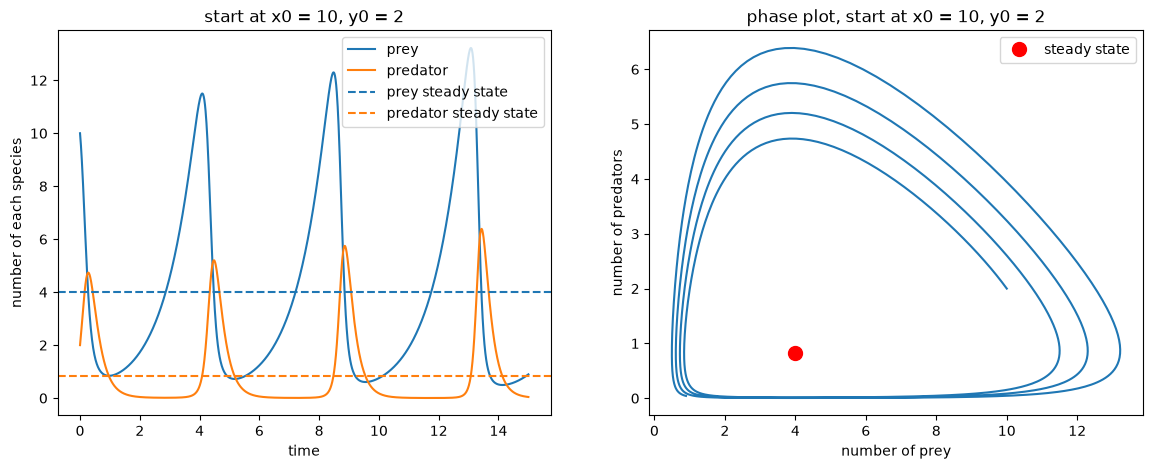

In [31]:
# plot the steady state on the timeseries and phase plot
time, u = run_model(10., 2., 0.01)
ax1, ax2 = plot_model(time, u, "start at x0 = 10, y0 = 2")
ax1.axhline(x_ss, color='tab:blue', linestyle='--', label='prey steady state')
ax1.axhline(y_ss, color='tab:orange', linestyle='--', label='predator steady state')
ax1.legend(loc='upper right')
ax2.plot(x_ss, y_ss, 'ro', markersize=10, label='steady state')
ax2.legend(loc='upper right')

prey goes from 4.0 to 4.0


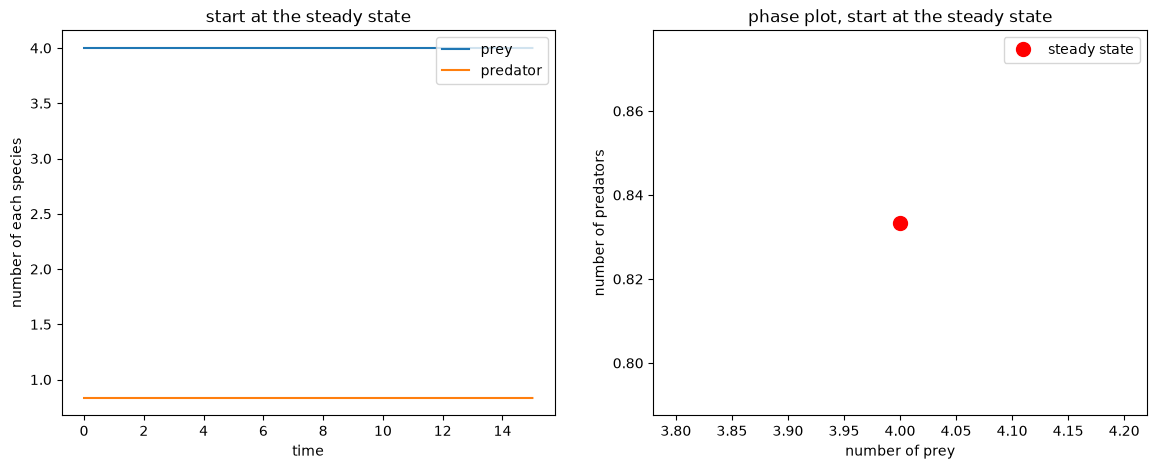

In [32]:
# what happens if we start exactly at the steady state?
time, u = run_model(x_ss, y_ss, 0.01)
ax1, ax2 = plot_model(time, u, "start at the steady state")
ax2.plot(x_ss, y_ss, 'ro', markersize=10, label='steady state')
ax2.legend(loc='upper right')
print("prey goes from", u[:,0].min(), "to", u[:,0].max())

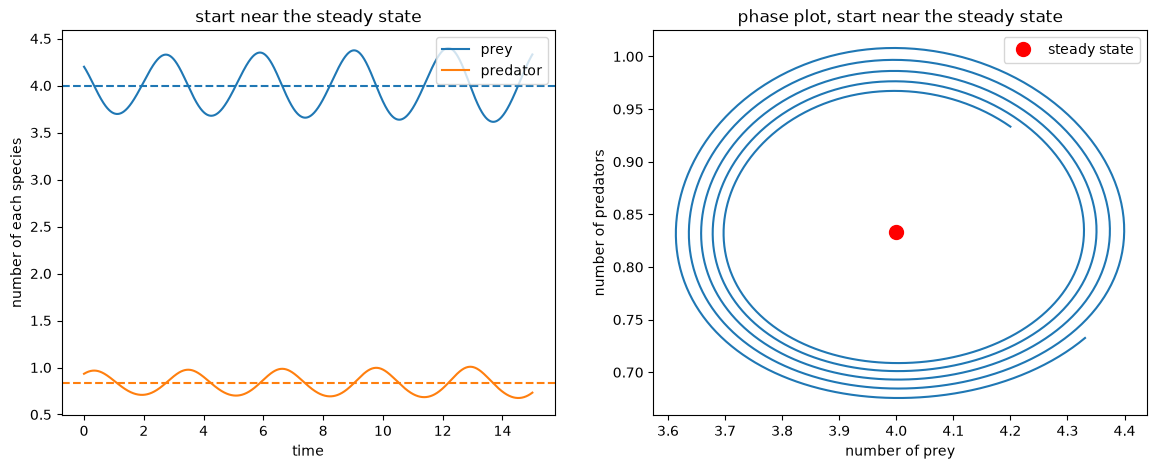

In [33]:
# what happens if we start near the steady state?
time, u = run_model(x_ss + 0.2, y_ss + 0.1, 0.01)
ax1, ax2 = plot_model(time, u, "start near the steady state")
ax1.axhline(x_ss, color='tab:blue', linestyle='--')
ax1.axhline(y_ss, color='tab:orange', linestyle='--')
ax2.plot(x_ss, y_ss, 'ro', markersize=10, label='steady state')
ax2.legend(loc='upper right')

#### E.3 A better algorithm
Do Exercise 1 again with a fourth order time stepping method called "Runge-Kutta 4" whose algorithm is given below. How do your answers differ? How does the dt, the timestep, affect your answer using this "higher order" algorithm?

In [34]:
def RK4(u,f,dt):
    # Runge Kutta 4th order method
    """Returns the solution at the next time-step using Runge Kutta fourth order (RK4) method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    #calculate slopes
    k1 = f(u)
    u1 = u + (dt/2.)*k1
    k2 = f(u1)
    u2 = u + (dt/2.)*k2
    k3 = f(u2)
    u3 = u + dt*k3
    k4 = f(u3)
    return u + (dt/6.)*(k1 + 2.*k2 + 2.*k3 + k4)

dt = 0.1  smallest prey number: 0.902  largest prey number: 10.854
dt = 0.01  smallest prey number: 0.902  largest prey number: 10.851
dt = 0.001  smallest prey number: 0.902  largest prey number: 10.851
dt = 0.0001  smallest prey number: 0.902  largest prey number: 10.851


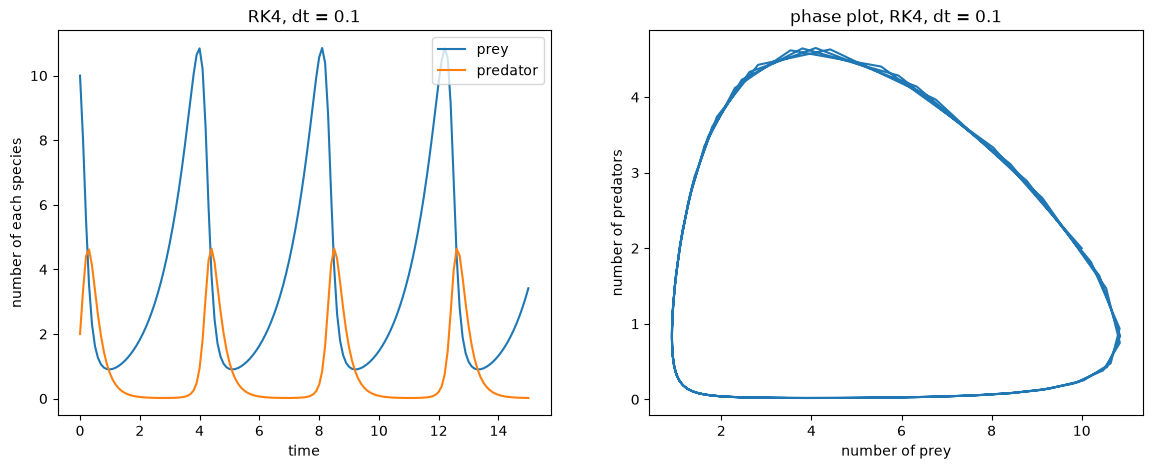

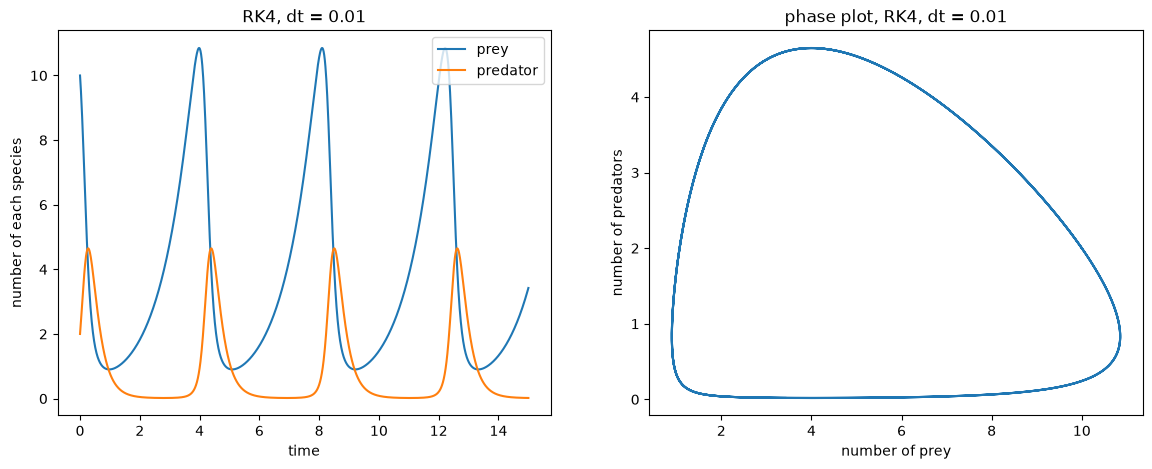

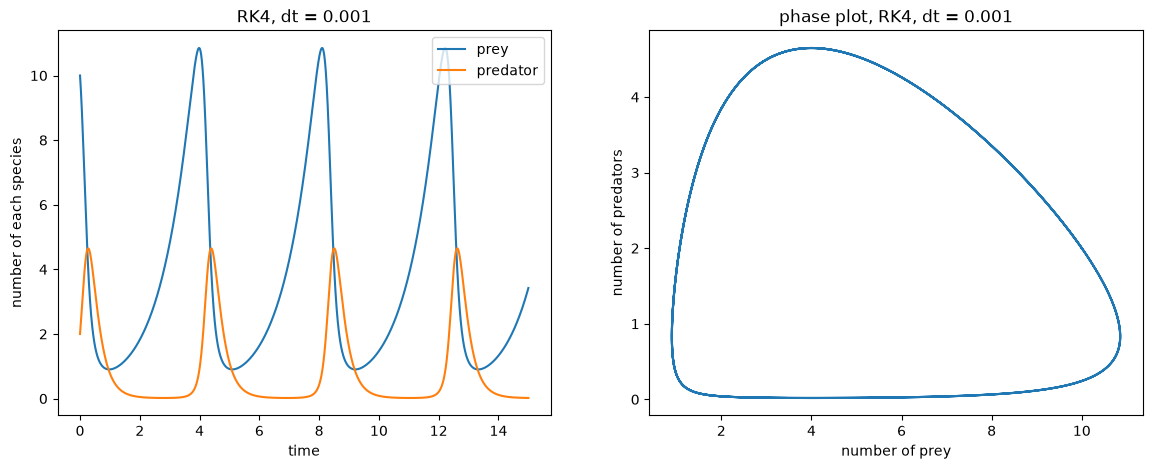

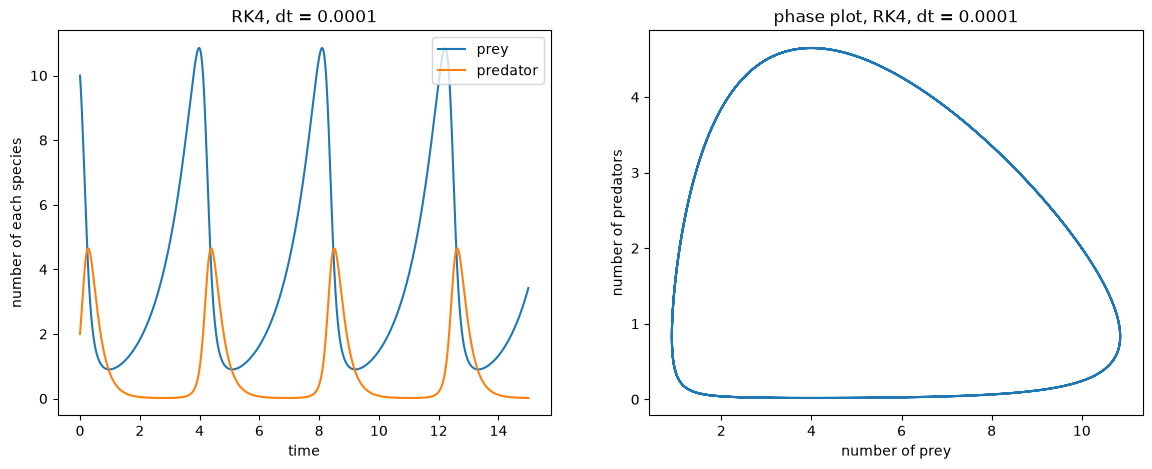

In [35]:
# Now, using RK4 instead of Euler
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

for dt in [0.1, 0.01, 0.001, 0.0001]:
    time, u = run_model(x0, y0, dt, step=RK4)
    plot_model(time, u, "RK4, dt = " + str(dt))
    print("dt =", dt, " smallest prey number:", u[:,0].min().round(3), " largest prey number:", u[:,0].max().round(3))

#### E.4 Exploring parameter space
Vary the interactions between species by changing $\alpha, \beta, \gamma, \delta$ and see what happens to the population evolution as well as phase plots. How does changing each parameter individually affect the system?

alpha x 2: steady state = (4.0, 1.667)  max prey = 10.06  max predator = 5.69
beta x 2: steady state = (4.0, 0.417)  max prey = 13.4  max predator = 3.16
gamma x 2: steady state = (8.0, 0.833)  max prey = 11.95  max predator = 2.29
delta x 2: steady state = (2.0, 0.833)  max prey = 10.33  max predator = 11.42


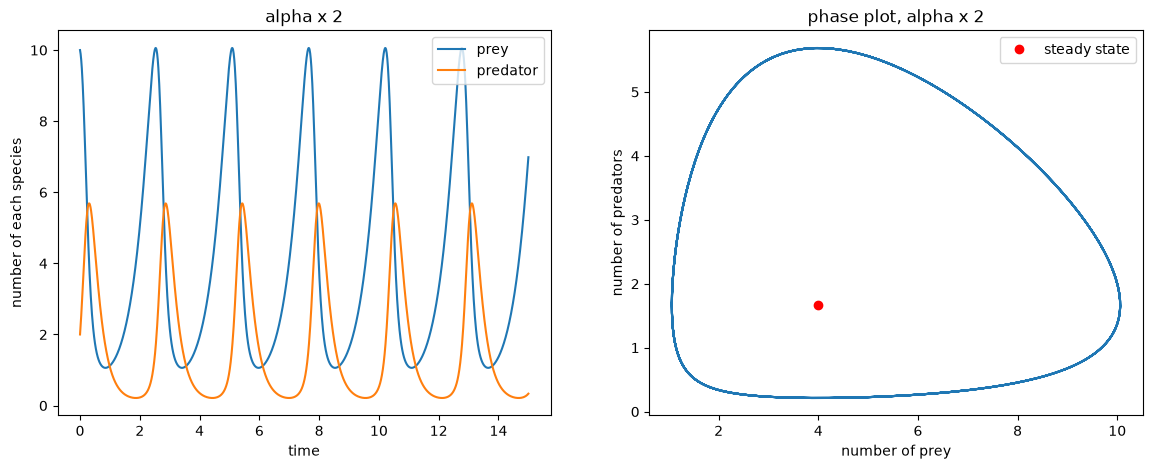

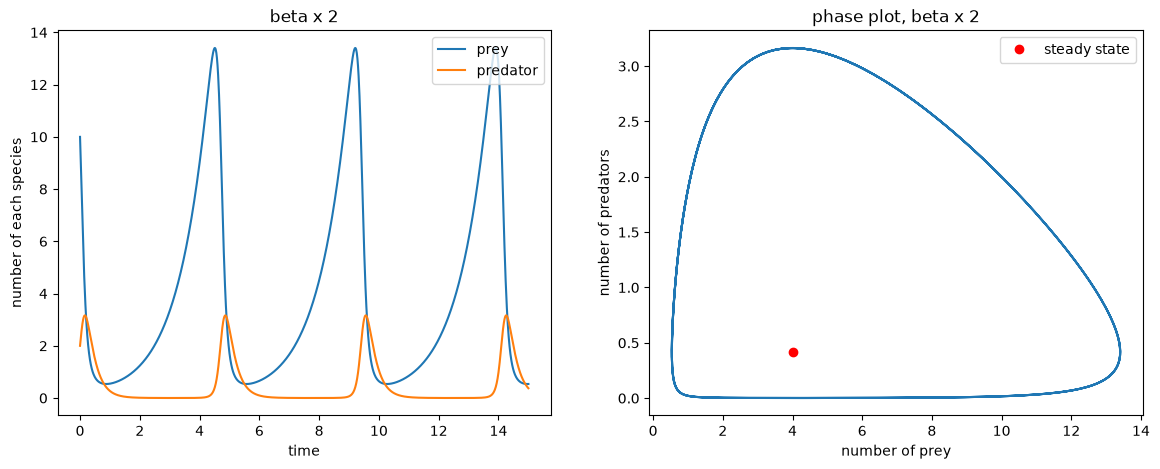

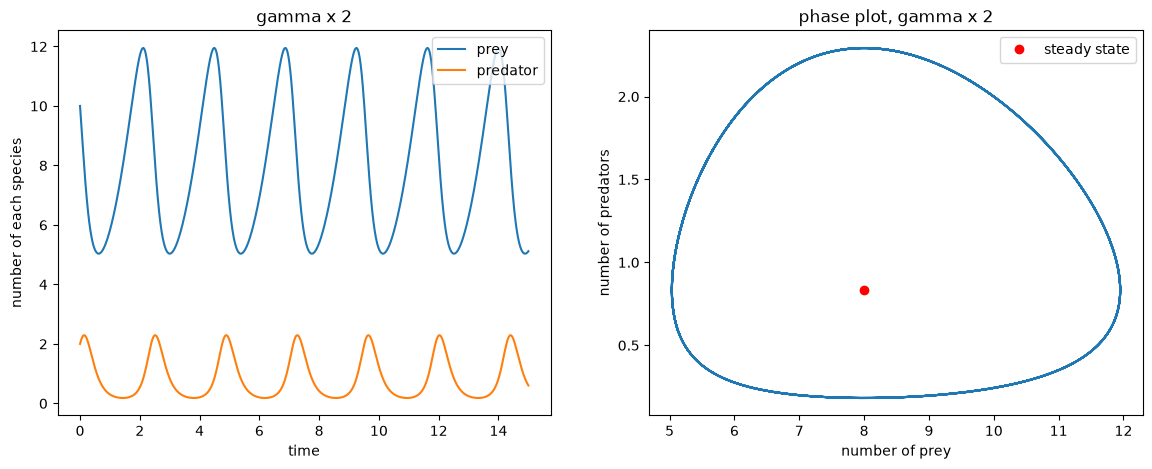

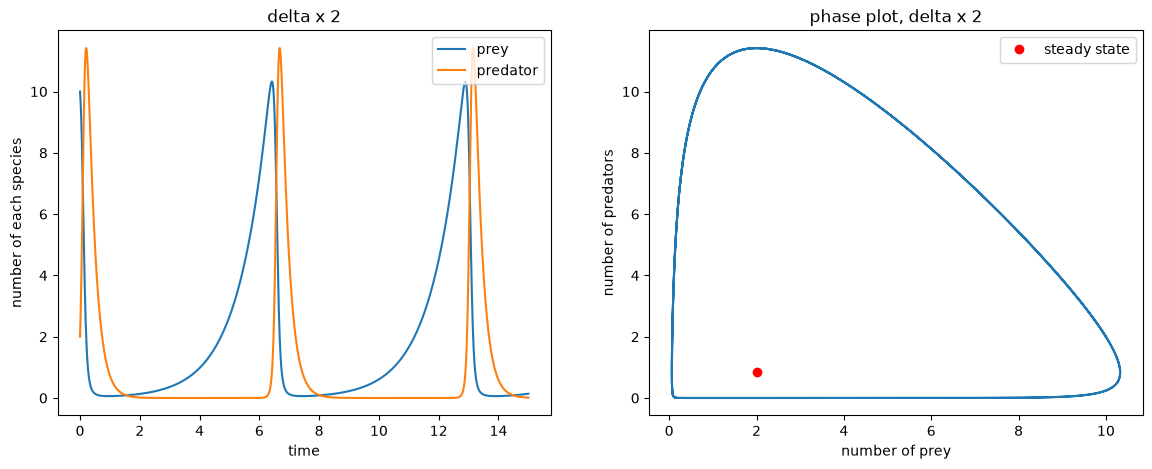

In [36]:
# for changes to come from parameters only, use  RK4 with dt = 0.01 
original = {"alpha": 1., "beta": 1.2, "gamma": 4., "delta": 1.}

for name in ["alpha", "beta", "gamma", "delta"]:
    # set all parameters back to the original values
    alpha, beta, gamma, delta = original["alpha"], original["beta"], original["gamma"], original["delta"]
    # doubling one of them
    if name == "alpha": alpha = 2 * alpha
    if name == "beta":  beta = 2 * beta
    if name == "gamma": gamma = 2 * gamma
    if name == "delta": delta = 2 * delta

    time, u = run_model(x0, y0, 0.01, step=RK4)
    ax1, ax2 = plot_model(time, u, name + " x 2")
    ax2.plot(gamma/delta, alpha/beta, 'ro', label='steady state')
    ax2.legend(loc='upper right')
    print(name, "x 2: steady state =", (gamma/delta, round(alpha/beta, 3)),
          " max prey =", u[:,0].max().round(2), " max predator =", u[:,1].max().round(2))

# setting the parameters to the original values
alpha, beta, gamma, delta = original["alpha"], original["beta"], original["gamma"], original["delta"]

#### E.5 (Advanced, required for grad students)
Modify the differential equations to include other types of interactions. See advanced predator prey example link at the top for ideas. You might add in a self-eating (i.e. $-ay^2$) term into the predator equation. Or do the zombie apocalypse example linked above.

**Adding the predator self-limitation (competition between the predators)**

I also added a $-a y^2$ term in the predator equation. This would make the predator compete with each other for different things that includes territory. They, hence, die faster

$dx/dt = \alpha x - \beta x y$

$dy/dt = \delta x y - \gamma y - a y^2$

New steady state: Here, the prey equation still gives $y = \alpha/\beta$. The predator equation, on the other hand, gives $\delta x - \gamma - a y = 0$, so $x = (\gamma + a\,\alpha/\beta)/\delta$.

new steady state: 4.416666666666667 0.8333333333333334
end of the run: [4.425 0.833]


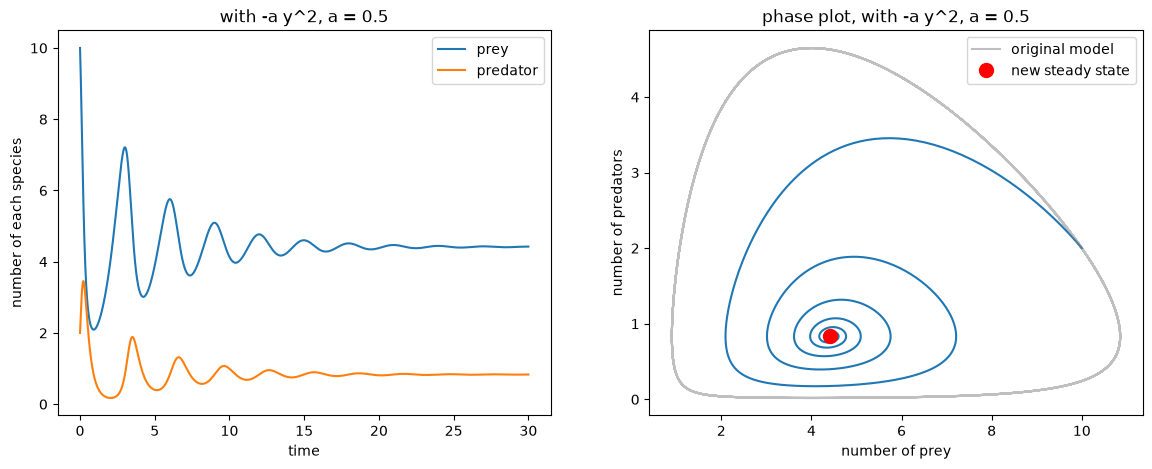

In [37]:
# new equations with the self-limiting term for predators
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.
a = 0.5      # strength of competition between predators

def f_self(u):
    """Lotka-Volterra with an extra -a*y^2 term in the predator equation"""
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x) - a*y**2])

# new steady state 
x_ss_new = (gamma + a*alpha/beta)/delta
y_ss_new = alpha/beta
print("new steady state:", x_ss_new, y_ss_new)

T = 30.0   # running longer to see what happens in the end
time, u_old = run_model(x0, y0, 0.01, step=RK4)               # original model
time, u_new = run_model(x0, y0, 0.01, step=RK4, func=f_self)  # with -a*y^2
T = 15.0   # setting back to the original

ax1, ax2 = plot_model(time, u_new, "with -a y^2, a = " + str(a))
ax2.plot(u_old[:,0], u_old[:,1], color='gray', alpha=0.5, label='original model')
ax2.plot(x_ss_new, y_ss_new, 'ro', markersize=10, label='new steady state')
ax2.legend(loc='upper right')

print("end of the run:", u_new[-1].round(3))